# 1. Kiểm tra work_activities

In [1]:
import sqlite3

db_path = "../data/database/career.db"



In [2]:
def valid_work_activities(db_path):
    with sqlite3.connect(db_path) as conn:

        # 1. Tổng số bản ghi
        total_rows = conn.execute("""
            SELECT COUNT(*)
            FROM occupation_work_activities
        """).fetchone()[0]

        # 2. Số activity unique
        total_activity = conn.execute(
            "SELECT COUNT(DISTINCT activity) FROM occupation_work_activities"
        ).fetchone()[0]
        # 3. Số occupations
        total_occupations = conn.execute("""
            SELECT COUNT(DISTINCT occupation_code)
            FROM occupation_work_activities
        """).fetchone()[0]
        # 4. Kiểm tra số activity của từng nghề
        invalid_occupation = conn.execute(
            """
            SELECT occupation_code, COUNT(*) as activity_count 
            FROM occupation_work_activities
            GROUP BY occupation_code
            HAVING activity_count != 41
            """
        ).fetchall()
        # 5. Kiểm tra giá trị NULL
        null_values = conn.execute("""
            SELECT
                SUM(CASE WHEN occupation_code IS NULL
                         THEN 1 ELSE 0 END),
                SUM(CASE WHEN activity IS NULL
                         THEN 1 ELSE 0 END),
                SUM(CASE WHEN importance_score IS NULL
                         THEN 1 ELSE 0 END),
                SUM(CASE WHEN level_score IS NULL
                         THEN 1 ELSE 0 END)
            FROM occupation_work_activities
        """).fetchone()

        # 6. Kiểm tra occupation_code có khớp bảng occupations không
        unmatched_occupations = conn.execute("""
            SELECT COUNT(DISTINCT wa.occupation_code)
            FROM occupation_work_activities AS wa
            LEFT JOIN occupations AS o
                ON wa.occupation_code = o.occupation_code
            WHERE o.occupation_code IS NULL
        """).fetchone()[0]

        # 7. Kiểm tra khóa ngoại
        foreign_key_errors = conn.execute("""
            PRAGMA foreign_key_check
        """).fetchall()

    print("=== WORK ACTIVITIES VALIDATION ===")
    print(f"Total rows: {total_rows}")
    print(f"Total occupations: {total_occupations}")
    print(f"Total activities: {total_activity}")
    print(f"Occupations without exactly 41 activities: "
          f"{len(invalid_occupation)}")
    print(f"NULL counts: {null_values}")
    print(f"Unmatched occupations: {unmatched_occupations}")
    print(f"Foreign key errors: {len(foreign_key_errors)}")

    assert total_rows == 911 * 41
    assert total_occupations == 911
    assert total_activity == 41
    assert len(invalid_occupation) == 0
    assert all(value == 0 for value in null_values)
    assert unmatched_occupations == 0
    assert len(foreign_key_errors) == 0

    print("\nAll validation checks passed!")
if __name__ == "__main__":
    valid_work_activities(db_path)

=== WORK ACTIVITIES VALIDATION ===
Total rows: 37351
Total occupations: 911
Total activities: 41
Occupations without exactly 41 activities: 0
NULL counts: (0, 0, 0, 0)
Unmatched occupations: 0
Foreign key errors: 0

All validation checks passed!


# 2. Xây dựng Feature matrix 41 LV

cần chuyển sang dạng rộng (wide format):

| occupation_code | Activity A | Activity B | Activity C | ... | Activity 41 |
|----------------|-----------:|-----------:|-----------:|-----|------------:|
| 15-1252.00 | 4.2 | 4.0 | 5.0 | ... | 3.8 |
| 15-1253.00 | 3.5 | 3.8 | 4.5 | ... | 4.1 |
| ... | ... | ... | ... | ... | ... |


Mỗi occupation lúc này được biểu diễn bằng một vector 41 chiều:
$
\mathbf{x}_i =
[x_{i1},x_{i2},\ldots,x_{i41}]
$

In [3]:
import pandas as pd

def load_work_activity_features(db_path):
    """
    Load Work Activities từ SQLite và tạo feature matrix 41 LV.

    Returns
    -------
    X_41 : pandas.DataFrame
        Rows: occupations
        Columns: 41 Work Activities
        Values: level_score
    """

    with sqlite3.connect(db_path) as conn:
        wa = pd.read_sql_query(
            """
            SELECT
                occupation_code,
                activity,
                level_score
            FROM occupation_work_activities
            ORDER BY occupation_code, activity
            """,
            conn
        )

    # Kiểm tra dữ liệu đầu vào
    if wa.empty:
        raise ValueError("occupation_work_activities is empty.")

    if wa.duplicated(["occupation_code", "activity"]).any():
        raise ValueError("Duplicate occupation-activity pairs detected.")

    if wa["level_score"].isna().any():
        raise ValueError("Missing level_score detected.")

    # Chuyển long fomat sang wide fomat
    X_41 = wa.pivot(
        index="occupation_code",
        columns="activity",
        values= "level_score"
    )
    # Làm sạch tên trục
    X_41.index.name = "occupation_code"
    X_41.columns.name = None

    # Kiểm tra kích thước
    if X_41.shape != (911, 41):
        raise ValueError(
            f"Unexpected matrix shape: {X_41.shape}. "
            "Expected (911, 41)."
        )

    # Kiểm tra dữ liệu thiếu sau pivot
    if X_41.isna().any().any():
        raise ValueError("Missing values detected after pivot.")

    
    return X_41
if __name__ == "__main__":
    X_41 = load_work_activity_features(db_path)

    print("Feature matrix shape:", X_41.shape)
    print("\nFirst 5 occupations:")
    print(X_41.head())

    print("\nMissing values:", X_41.isna().sum().sum())

Feature matrix shape: (911, 41)

First 5 occupations:
                 Analyzing Data or Information  \
occupation_code                                  
11-1011.00                                4.84   
11-1011.03                                4.81   
11-1021.00                                4.27   
11-2011.00                                2.85   
11-2021.00                                4.51   

                 Assisting and Caring for Others  \
occupation_code                                    
11-1011.00                                  3.10   
11-1011.03                                  2.67   
11-1021.00                                  3.03   
11-2011.00                                  2.95   
11-2021.00                                  3.18   

                 Coaching and Developing Others  \
occupation_code                                   
11-1011.00                                 5.85   
11-1011.03                                 4.78   
11-1021.00                

# EDA cho 41 feature

In [4]:


# Thống kê từng activity
activity_stats = X_41.describe().T

activity_stats = activity_stats[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

print(activity_stats.round(3))

                                                     mean    std   min    25%  \
Analyzing Data or Information                       3.755  1.248  0.34  2.820   
Assisting and Caring for Others                     3.053  1.287  0.68  2.150   
Coaching and Developing Others                      3.507  0.992  0.55  2.760   
Communicating with People Outside the Organization  3.536  1.287  0.12  2.675   
Communicating with Supervisors, Peers, or Subor...  4.409  0.815  1.84  3.870   
Controlling Machines and Processes                  2.847  1.524  0.06  1.540   
Coordinating the Work and Activities of Others      3.467  0.953  0.68  2.790   
Developing Objectives and Strategies                3.248  1.009  0.15  2.525   
Developing and Building Teams                       2.998  0.954  0.49  2.310   
Documenting/Recording Information                   3.629  1.020  0.52  2.970   
Drafting, Laying Out, and Specifying Technical ...  1.893  1.295  0.00  0.860   
Establishing and Maintaining

In [5]:
feature_std = X_41.std().sort_values()

print("5 activities with lowest standard deviation:")
print(feature_std.head(5))

print("\n5 activities with highest standard deviation:")
print(feature_std.tail(5))

5 activities with lowest standard deviation:
Judging the Qualities of Objects, Services, or People                              0.802606
Establishing and Maintaining Interpersonal Relationships                           0.806612
Communicating with Supervisors, Peers, or Subordinates                             0.814611
Estimating the Quantifiable Characteristics of Products, Events, or Information    0.859628
Monitoring Processes, Materials, or Surroundings                                   0.861343
dtype: float64

5 activities with highest standard deviation:
Performing for or Working Directly with the Public    1.365116
Performing General Physical Activities                1.473508
Repairing and Maintaining Mechanical Equipment        1.480088
Controlling Machines and Processes                    1.523532
Handling and Moving Objects                           1.662071
dtype: float64


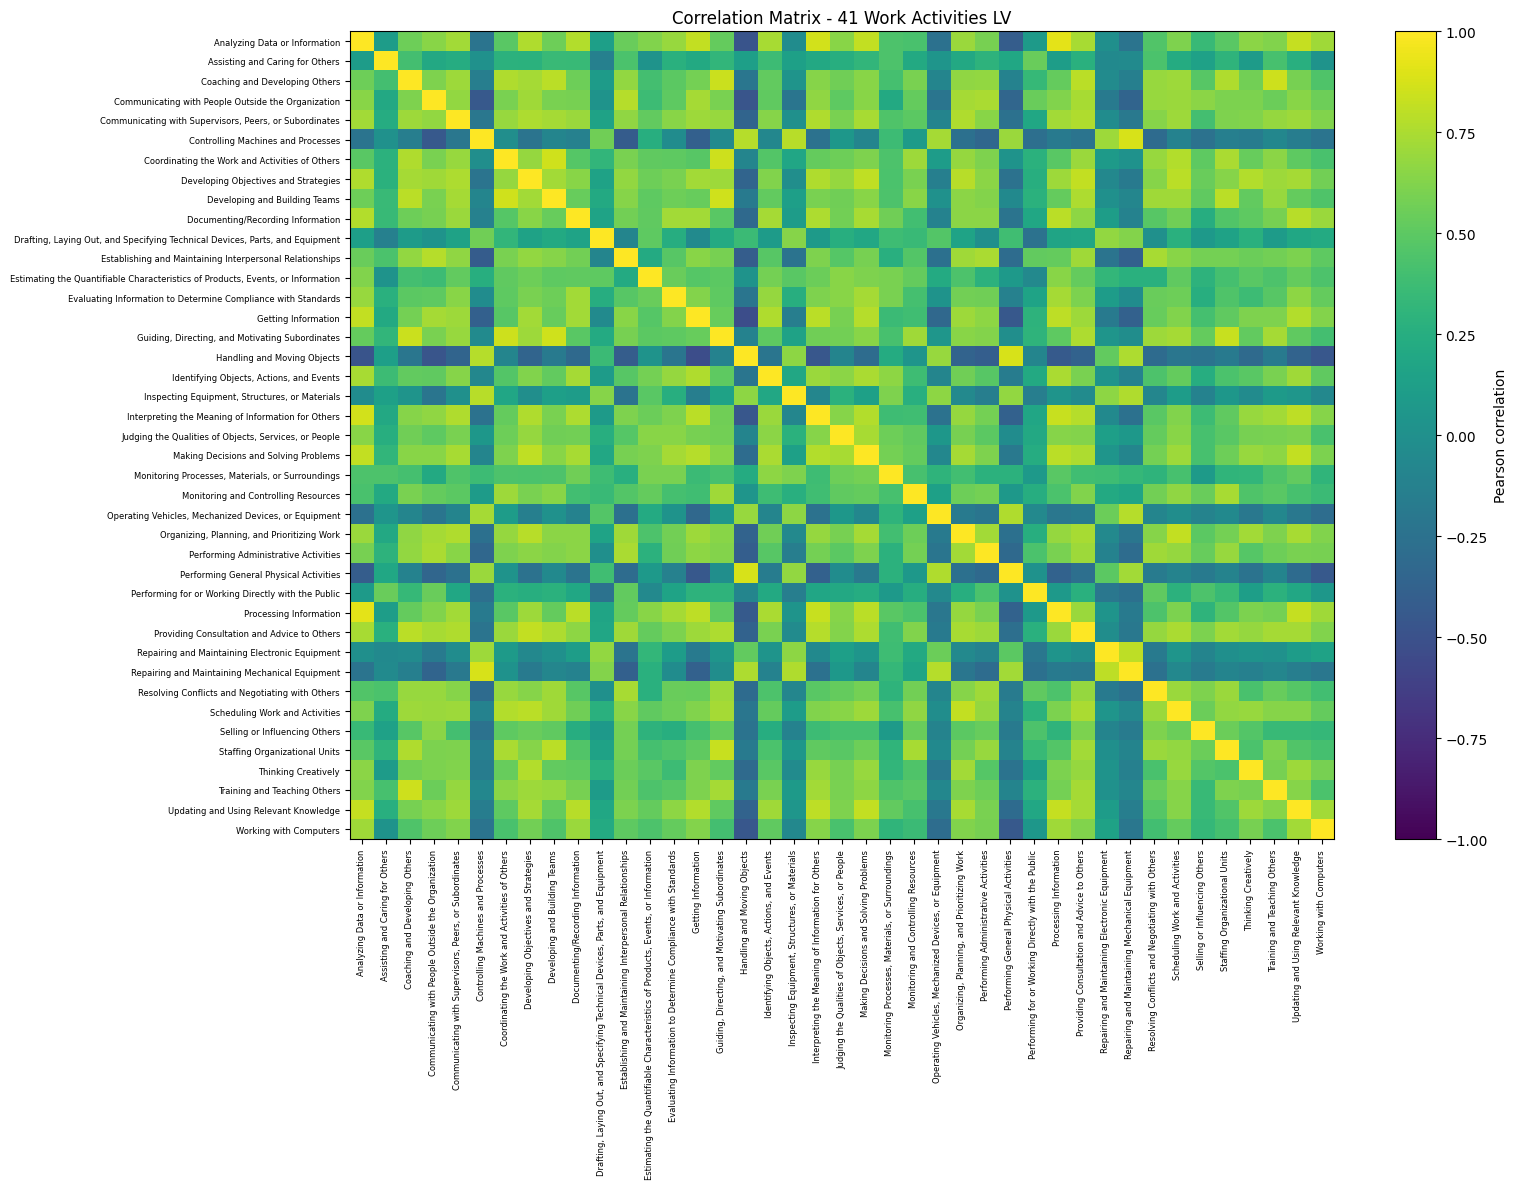

In [6]:
import matplotlib.pyplot as plt

corr = X_41.corr()

plt.figure(figsize=(16, 12))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90,
    fontsize=6
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns,
    fontsize=6
)

plt.title("Correlation Matrix - 41 Work Activities LV")
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
# Chỉ lấy nửa trên của ma trận, bỏ đường chéo
upper_mask = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)

upper_corr = corr.where(upper_mask)

# Chuyển ma trận thành danh sách các cặp feature
corr_pairs = (
    upper_corr.stack()
    .rename("correlation")
    .reset_index()
)

corr_pairs.columns = [
    "activity_1",
    "activity_2",
    "correlation"
]

# 10 cặp tương quan dương mạnh nhất
strongest_positive = (
    corr_pairs
    .sort_values("correlation", ascending=False)
    .head(10)
)

# 10 cặp tương quan âm mạnh nhất
strongest_negative = (
    corr_pairs
    .sort_values("correlation", ascending=True)
    .head(10)
)

print("=== 10 STRONGEST POSITIVE CORRELATIONS ===")
print(strongest_positive.to_string(index=False))

print("\n=== 10 STRONGEST NEGATIVE CORRELATIONS ===")
print(strongest_negative.to_string(index=False))

=== 10 STRONGEST POSITIVE CORRELATIONS ===
                                     activity_1                                         activity_2  correlation
                  Analyzing Data or Information                             Processing Information     0.920472
             Controlling Machines and Processes     Repairing and Maintaining Mechanical Equipment     0.882415
                    Handling and Moving Objects             Performing General Physical Activities     0.879312
                  Analyzing Data or Information Interpreting the Meaning of Information for Others     0.863153
                  Developing and Building Teams    Guiding, Directing, and Motivating Subordinates     0.854677
 Coordinating the Work and Activities of Others                      Developing and Building Teams     0.852837
 Coordinating the Work and Activities of Others    Guiding, Directing, and Motivating Subordinates     0.849793
                 Coaching and Developing Others              

## PCA

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Chuẩn hóa 41 features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_41)

# PCA để khảo sát tỷ lệ phương sai tích lũy
pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)

cumulative_variance = (
    pca_full.explained_variance_ratio_.cumsum()
)

pca_summary = pd.DataFrame({
    "n_components": range(1, len(cumulative_variance) + 1),
    "explained_variance_ratio": (
        pca_full.explained_variance_ratio_
    ),
    "cumulative_variance": cumulative_variance
})

print(pca_summary.to_string(index=False))

# Số thành phần cần giữ để giải thích ít nhất 90% phương sai
n_components_90 = (
    np.searchsorted(cumulative_variance, 0.90) + 1
)

print(
    f"\nComponents needed for 90% variance: "
    f"{n_components_90}"
)

 n_components  explained_variance_ratio  cumulative_variance
            1                  0.479734             0.479734
            2                  0.162504             0.642238
            3                  0.075050             0.717288
            4                  0.044652             0.761940
            5                  0.026203             0.788142
            6                  0.021465             0.809607
            7                  0.020486             0.830093
            8                  0.015191             0.845284
            9                  0.013427             0.858711
           10                  0.010957             0.869668
           11                  0.010244             0.879912
           12                  0.008654             0.888566
           13                  0.007657             0.896223
           14                  0.007003             0.903227
           15                  0.006941             0.910167
           16           

3 kết luận quan trọng từ kết quả :
1. 41 Work Activities có cấu trúc tương quan rõ ràng. Ví dụ, Analyzing Data or Information và Processing Information có tương quan r=0.920, trong khi Handling and Moving Objects tương quan âm với một số hoạt động xử lý thông tin.  
  
2. PCA có khả năng giảm chiều đáng kể. Chỉ cần 14 components để giữ ít nhất 90% phương sai của 41 features đã chuẩn hóa — giảm từ 41 xuống 14 chiều.  

3. Chưa thể kết luận PCA tốt hơn 41 LV. Giữ được 90% phương sai không đồng nghĩa với tạo ra các cluster tốt hơn.